In [1]:
import os
os.makedirs('/root/.kaggle', exist_ok=True)

with open('/root/.kaggle/access_token', 'w') as f:
    f.write('KGAT_9ff892943d6d52e13ca6e53a2786d62b')  # paste your fresh token directly in the notebook, don't share it elsewhere

!chmod 600 /root/.kaggle/access_token

In [ ]:
!pip install kaggle
!kaggle datasets list

ref                                                                 title                                                 size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------------------  ----------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
dreaddevelopment/raptor-knee-widedense                              Knee MRI model weights: twelve findings          543320725  2026-08-23 04:12:20.703000            581         34  0.9375           
debayank2024/netflix-movies-and-series                              Netflix Movies and Series                          1400865  2026-07-27 09:40:46.527000           9914        244  1                
datascikhan/e-commerce-sales-and-customer-analytics                 🛒 E-Commerce Sales Analytics Dataset              29815424  2026-08-25 08:00:46.013000           1718         43  1                


In [2]:
!kaggle datasets list -s compcars

ref                                                title                                             size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------  -----------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
renancostaalencar/compcars                         CUHK CompCars Dataset                      16533899407  2022-01-14 17:17:44.937000           4854         30  0.6875           
hamedahangari/internal-and-external-parts-of-cars  Internal and External Parts of Cars         3364274124  2021-04-27 14:04:44.643000            938         18  0.4375           
wjwj31415/compcars                                 compcars                                    3094558374  2022-04-21 13:27:06.517000             43          1  0.125            
negoescubiancaelena/compcars-239-classes           CompCars 239 Classes                                 0

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############

download_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle'
os.makedirs(download_path, exist_ok=True)

!kaggle datasets download -d renancostaalencar/compcars -p {download_path}

Dataset URL: https://www.kaggle.com/datasets/renancostaalencar/compcars
License(s): unknown
compcars.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
import zipfile

zip_files = [f for f in os.listdir(download_path) if f.endswith('.zip')]
print(f"Found zip file: {zip_files}")

zip_path = os.path.join(download_path, zip_files[0])
extract_path = os.path.join(download_path, 'extracted')

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Found zip file: ['compcars.zip']


KeyboardInterrupt: 

In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
import zipfile
from tqdm import tqdm

zip_path = os.path.join(download_path, zip_files[0])
extract_path = os.path.join(download_path, 'extracted')

with zipfile.ZipFile(zip_path, 'r') as zf:
    for member in tqdm(zf.infolist(), desc='Extracting'):
        zf.extract(member, path=extract_path)

NameError: name 'zip_files' is not defined

In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
extract_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted'  # adjust to wherever this landed

import os
for root, dirs, files in os.walk(extract_path):
    if files:
        print(root, '->', len(files), 'files', '| sample:', files[:2])
    if len(dirs) > 0 and root == extract_path:
        print('Top-level folders:', dirs)

Top-level folders: ['image', 'label']
/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/image/1/1101/2011 -> 18 files | sample: ['07b90decb92ba6.jpg', '2272c7d324cf79.jpg']
/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/image/1/1102/2011 -> 9 files | sample: ['602de0afa91b7e.jpg', '12226a5418fcff.jpg']
/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/image/1/1102/2012 -> 3 files | sample: ['88033a30c74ec0.jpg', '4a12e2acda627c.jpg']
/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/image/1/1103/2011 -> 21 files | sample: ['02a39da5d64292.jpg', '038d44fa75d4a3.jpg']
/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/image/1/1103/2013 -> 3 files | sample: ['4dc25a3af47177.jpg', 'd2db1ea26ab012.jpg']
/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/image/1/1103/2015 -> 4 files | sample: ['32127e81a63285.jpg'

KeyboardInterrupt: 

In [4]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
print(os.listdir(extract_path))  # full top-level listing again, to catch anything besides image/label

NameError: name 'extract_path' is not defined

In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
download_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle'
print(os.listdir(download_path))

['compcars.zip', 'extracted']


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
import zipfile

zip_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/compcars.zip'

with zipfile.ZipFile(zip_path, 'r') as zf:
    names = zf.namelist()
    top_level_folders = set(n.split('/')[0] for n in names if '/' in n)
    print(f"Total entries in zip: {len(names)}")
    print(f"Top-level folders in zip: {top_level_folders}")

Total entries in zip: 301095
Top-level folders in zip: {'train_test_split', 'image', 'part', 'misc', 'label'}


In [14]:
extract_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted'
print(os.listdir(extract_path))

['image', 'label', 'misc']


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
import zipfile
from tqdm import tqdm

zip_path = '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/compcars.zip'
local_extract_path = '/content/compcars_local'  # LOCAL disk, not Drive

with zipfile.ZipFile(zip_path, 'r') as zf:
    all_names = zf.namelist()
    # Only extract the folders that are missing
    missing_folders = ('misc/', 'part/', 'train_test_split/')
    to_extract = [n for n in all_names if n.startswith(missing_folders)]
    print(f"Files to extract: {len(to_extract)}")

    for name in tqdm(to_extract, desc='Extracting missing folders'):
        zf.extract(name, path=local_extract_path)

print("Done extracting missing folders locally.")

Files to extract: 27643


Extracting missing folders: 100%|██████████| 27643/27643 [01:27<00:00, 316.86it/s]

Done extracting missing folders locally.


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
print(os.listdir(local_extract_path))

['train_test_split', 'misc', 'part']


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
import shutil
shutil.copytree(
    os.path.join(local_extract_path, 'misc'),
    '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/misc'
)

'/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/misc'

In [5]:
import pandas as pd
from PIL import Image

In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
import random

def inspect_dataset_sample(root_dir, sample_size=500):
    all_image_paths = []
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                all_image_paths.append(os.path.join(dirpath, fname))

    print(f"Total images found: {len(all_image_paths)}")
    sample_paths = random.sample(all_image_paths, min(sample_size, len(all_image_paths)))

    records = []
    for fpath in tqdm(sample_paths, desc='Inspecting sample'):
        try:
            with Image.open(fpath) as img:
                width, height = img.size
            records.append({'file_path': fpath, 'width': width, 'height': height,
                             'size_kb': os.path.getsize(fpath) / 1024, 'corrupted': False})
        except Exception:
            records.append({'file_path': fpath, 'width': None, 'height': None,
                             'size_kb': None, 'corrupted': True})
    return pd.DataFrame(records)

df = inspect_dataset_sample(os.path.join(extract_path, 'image'), sample_size=500)
print(f"Sample size: {len(df)}")
print(f"Corrupted in sample: {df['corrupted'].sum()}")
df = inspect_dataset_sample(os.path.join(extract_path, 'image'), sample_size=500)
print(f"Sample size: {len(df)}")
print(f"Corrupted in sample: {df['corrupted'].sum()}")

Total images found: 136726


Inspecting sample: 100%|██████████| 500/500 [00:00<00:00, 444029.64it/s]

Sample size: 500
Corrupted in sample: 500


Total images found: 136726


Inspecting sample: 100%|██████████| 500/500 [00:00<00:00, 462539.04it/s]

Sample size: 500
Corrupted in sample: 500


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
sample_path = random.choice(all_image_paths) if 'all_image_paths' in dir() else None

# Get one file path directly
test_paths = []
for dirpath, _, filenames in os.walk(os.path.join(extract_path, 'image')):
    for fname in filenames:
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            test_paths.append(os.path.join(dirpath, fname))
            break
    if test_paths:
        break

print(f"Testing path: {test_paths[0]}")
print(f"File exists: {os.path.exists(test_paths[0])}")

try:
    img = Image.open(test_paths[0])
    print(f"Opened successfully: {img.size}")
except Exception as e:
    print(f"Error: {e}")

Testing path: /content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/image/1/1101/2011/07b90decb92ba6.jpg
File exists: True
Opened successfully: (800, 567)


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
df = inspect_dataset_sample(os.path.join(extract_path, 'image'), sample_size=500)
print(f"Sample size: {len(df)}")
print(f"Corrupted in sample: {df['corrupted'].sum()}")

Total images found: 136726


Inspecting sample: 100%|██████████| 500/500 [01:52<00:00,  4.43it/s]

Sample size: 500
Corrupted in sample: 0


In [ ]:
###don't RUNNNNNNNNNNNNNN THIS CELLLLLL###############
import shutil
from tqdm import tqdm

local_image_path = '/content/compcars_images_local'
source_path = os.path.join(extract_path, 'image')

# Collect all files first (fast — just listing, not copying)
all_files = []
for dirpath, dirs, filenames in os.walk(source_path):
    for fname in filenames:
        rel_dir = os.path.relpath(dirpath, source_path)
        all_files.append((os.path.join(dirpath, fname), rel_dir, fname))

print(f"Total files to copy: {len(all_files)}")

# Copy with visible progress
for src_file, rel_dir, fname in tqdm(all_files, desc='Copying to local disk'):
    dest_dir = os.path.join(local_image_path, rel_dir)
    os.makedirs(dest_dir, exist_ok=True)
    shutil.copy2(src_file, os.path.join(dest_dir, fname))

print("Copy complete.")

Total files to copy: 136726


Copying to local disk:   4%|▍         | 5439/136726 [18:47<7:33:39,  4.82it/s]


KeyboardInterrupt: 

In [7]:
!cp "/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/compcars.zip" "/content/compcars.zip"
print("Zip copied locally.")

Zip copied locally.


In [8]:
import zipfile
from tqdm import tqdm

with zipfile.ZipFile("/content/compcars.zip", 'r') as zf:
    image_files = [n for n in zf.namelist() if n.startswith('image/')]
    print(f"Extracting {len(image_files)} image files...")
    for name in tqdm(image_files, desc='Extracting locally'):
        zf.extract(name, path="/content/compcars_local")

print("Done.")

Extracting 136726 image files...


Extracting locally: 100%|██████████| 136726/136726 [02:35<00:00, 879.86it/s] 

Done.


In [9]:
def inspect_dataset_full(root_dir):
    all_image_paths = []
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                all_image_paths.append(os.path.join(dirpath, fname))
    print(f"Total images: {len(all_image_paths)}")

    records = []
    for fpath in tqdm(all_image_paths, desc='Inspecting'):
        try:
            with Image.open(fpath) as img:
                width, height = img.size
            records.append({'file_path': fpath, 'width': width, 'height': height,
                             'size_kb': os.path.getsize(fpath) / 1024, 'corrupted': False})
        except Exception:
            records.append({'file_path': fpath, 'width': None, 'height': None,
                             'size_kb': None, 'corrupted': True})
    return pd.DataFrame(records)

df_full = inspect_dataset_full("/content/compcars_local/image")
print(f"Total: {len(df_full)}, Corrupted: {df_full['corrupted'].sum()}")

Total images: 136726


Inspecting: 100%|██████████| 136726/136726 [02:39<00:00, 857.68it/s]


Total: 136726, Corrupted: 0


In [10]:
os.makedirs('/content/drive/MyDrive/capstone-vehicle-metadata/outputs', exist_ok=True)
df_full.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_inventory_full.csv', index=False)
print("Saved.")

Saved.


In [11]:
print(f"Total images: {len(df_full)}")
print(f"Corrupted: {df_full['corrupted'].sum()}")
print(df_full[['width', 'height', 'size_kb']].describe())

Total images: 136726
Corrupted: 0
               width         height        size_kb
count  136726.000000  136726.000000  136726.000000
mean      851.817343     587.545302      94.152629
std        60.688195      51.378273      35.996220
min       400.000000     267.000000      19.422852
25%       800.000000     567.000000      66.987305
50%       800.000000     567.000000      86.287598
75%       908.000000     626.000000     114.949219
max      1170.000000    1392.000000     407.708008


In [12]:
import pandas as pd
check = pd.read_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_inventory_full.csv')
print(f"Rows in saved file: {len(check)}")
check.head()

Rows in saved file: 136726


,file_path,width,height,size_kb,corrupted
0,/content/compcars_local/image/102/289/2010/837...,908,626,88.266602,False
1,/content/compcars_local/image/102/289/2010/768...,908,626,84.104492,False
2,/content/compcars_local/image/102/289/2010/282...,800,567,108.842773,False
3,/content/compcars_local/image/102/289/2010/328...,800,567,124.857422,False
4,/content/compcars_local/image/102/289/2010/cf6...,800,567,72.586914,False


In [15]:
misc_path = os.path.join(extract_path, 'misc')
print(os.listdir(misc_path))

['make_model_name.mat', 'car_type.mat', 'attributes.txt']


In [16]:
from scipy.io import loadmat

make_model_data = loadmat(os.path.join(misc_path, 'make_model_name.mat'))
print("Keys:", make_model_data.keys())

# Inspect each non-metadata key
for key in make_model_data:
    if not key.startswith('__'):
        print(f"\n{key}: shape={make_model_data[key].shape}, sample={make_model_data[key][:5]}")

Keys: dict_keys(['__header__', '__version__', '__globals__', 'make_names', 'model_names'])

make_names: shape=(163, 1), sample=[[array(['ABT'], dtype='<U3')]
 [array(['BAC'], dtype='<U3')]
 [array(['Conquest'], dtype='<U8')]
 [array(['DS'], dtype='<U2')]
 [array(['Dacia'], dtype='<U5')]]

model_names: shape=(2004, 1), sample=[[array(['Audi A3 hatchback'], dtype='<U17')]
 [array(['Audi A4L'], dtype='<U8')]
 [array(['Audi A6L'], dtype='<U8')]
 [array(['Audi Q3'], dtype='<U7')]
 [array(['Audi Q5'], dtype='<U7')]]


In [17]:
car_type_data = loadmat(os.path.join(misc_path, 'car_type.mat'))
print("Keys:", car_type_data.keys())

for key in car_type_data:
    if not key.startswith('__'):
        print(f"\n{key}: shape={car_type_data[key].shape}, sample={car_type_data[key][:5]}")

Keys: dict_keys(['__header__', '__version__', '__globals__', 'types'])

types: shape=(1, 12), sample=[[array(['MPV'], dtype='<U3') array(['SUV'], dtype='<U3')
  array(['sedan'], dtype='<U5') array(['hatchback'], dtype='<U9')
  array(['minibus'], dtype='<U7') array(['fastback'], dtype='<U8')
  array(['estate'], dtype='<U6') array(['pickup'], dtype='<U6')
  array(['hardtop convertible'], dtype='<U19')
  array(['sports'], dtype='<U6') array(['crossover'], dtype='<U9')
  array(['convertible'], dtype='<U11')]]


In [18]:
with open(os.path.join(misc_path, 'attributes.txt'), 'r') as f:
    lines = f.readlines()

print(f"Total lines: {len(lines)}")
print("First 10 lines:")
for line in lines[:10]:
    print(line.strip())

Total lines: 1717
First 10 lines:
model_id maximum_speed displacement door_number seat_number type
1 235 1.8 5 5 4
2 220 1.8 4 5 3
3 228 2.0 4 5 3
4 230 2.0 5 5 2
5 234 3.0 5 5 2
9 0 0.0 0 0 0
11 242 1.8 4 5 3
12 250 4.2 2 4 3
13 250 4.0 5 4 6


In [19]:
model_names_raw = make_model_data['model_names']
model_id_to_name = {}

for i in range(len(model_names_raw)):
    entry = model_names_raw[i][0]
    if entry.size > 0:  # skip empty entries
        model_id_to_name[i+1] = entry[0]
    else:
        model_id_to_name[i+1] = None  # mark as missing/unknown

print(f"Total models mapped: {len(model_id_to_name)}")
print(f"Missing/empty entries: {sum(1 for v in model_id_to_name.values() if v is None)}")
print(f"Sample: {model_id_to_name[1]}")

Total models mapped: 2004
Missing/empty entries: 288
Sample: Audi A3 hatchback


In [20]:
make_names_raw = make_model_data['make_names']
make_id_to_name = {}

for i in range(len(make_names_raw)):
    entry = make_names_raw[i][0]
    if entry.size > 0:
        make_id_to_name[i+1] = entry[0]
    else:
        make_id_to_name[i+1] = None

print(f"Total makes mapped: {len(make_id_to_name)}")
print(f"Missing/empty entries: {sum(1 for v in make_id_to_name.values() if v is None)}")

Total makes mapped: 163
Missing/empty entries: 0


In [21]:
types_raw = car_type_data['types'][0]
type_id_to_bodytype = {}

for i in range(len(types_raw)):
    entry = types_raw[i]
    if entry.size > 0:
        type_id_to_bodytype[i+1] = entry[0]
    else:
        type_id_to_bodytype[i+1] = None

In [22]:
# --- car_type.mat mapping (same safety pattern) ---
types_raw = car_type_data['types'][0]
type_id_to_bodytype = {}

for i in range(len(types_raw)):
    entry = types_raw[i]
    if entry.size > 0:
        type_id_to_bodytype[i+1] = entry[0]
    else:
        type_id_to_bodytype[i+1] = None

print(f"Body types mapped: {type_id_to_bodytype}")

Body types mapped: {1: np.str_('MPV'), 2: np.str_('SUV'), 3: np.str_('sedan'), 4: np.str_('hatchback'), 5: np.str_('minibus'), 6: np.str_('fastback'), 7: np.str_('estate'), 8: np.str_('pickup'), 9: np.str_('hardtop convertible'), 10: np.str_('sports'), 11: np.str_('crossover'), 12: np.str_('convertible')}


In [23]:
# --- Load attributes.txt ---
attrs_df = pd.read_csv(
    os.path.join(misc_path, 'attributes.txt'),
    sep=' '
)

attrs_df['body_type'] = attrs_df['type'].map(type_id_to_bodytype)
attrs_df['model_name'] = attrs_df['model_id'].map(model_id_to_name)

print(f"Total rows: {len(attrs_df)}")
print(f"Missing body_type: {attrs_df['body_type'].isna().sum()}")
print(f"Missing model_name: {attrs_df['model_name'].isna().sum()}")
attrs_df.head(10)

Total rows: 1716
Missing body_type: 748
Missing model_name: 0


,model_id,maximum_speed,displacement,door_number,seat_number,type,body_type,model_name
0,1,235,1.8,5,5,4,hatchback,Audi A3 hatchback
1,2,220,1.8,4,5,3,sedan,Audi A4L
2,3,228,2.0,4,5,3,sedan,Audi A6L
3,4,230,2.0,5,5,2,SUV,Audi Q3
4,5,234,3.0,5,5,2,SUV,Audi Q5
5,9,0,0.0,0,0,0,NaN,Audi A6
6,11,242,1.8,4,5,3,sedan,Audi A3 sedan
7,12,250,4.2,2,4,3,sedan,Audi RS5
8,13,250,4.0,5,4,6,fastback,Audi RS7
9,14,0,0.0,0,0,0,NaN,Audi RS4


In [24]:
def extract_ids_from_path(fpath):
    parts = fpath.split('/')
    # path structure: .../image/<make_id>/<model_id>/<year>/<filename>.jpg
    idx = parts.index('image')
    make_id = int(parts[idx+1])
    model_id = int(parts[idx+2])
    year = parts[idx+3]
    return make_id, model_id, year

df_full[['make_id', 'model_id', 'year']] = df_full['file_path'].apply(
    lambda x: pd.Series(extract_ids_from_path(x))
)

df_full['make'] = df_full['make_id'].map(make_id_to_name)
df_full = df_full.merge(attrs_df[['model_id', 'model_name', 'body_type']], on='model_id', how='left')

print(f"Missing make: {df_full['make'].isna().sum()}")
print(f"Missing body_type: {df_full['body_type'].isna().sum()}")
df_full.head(10)

Missing make: 0
Missing body_type: 38884


,file_path,width,height,size_kb,corrupted,make_id,model_id,year,make,model_name,body_type
0,/content/compcars_local/image/102/289/2010/837...,908,626,88.266602,False,102,289,2010,Peugeot,Peugeot SR1,NaN
1,/content/compcars_local/image/102/289/2010/768...,908,626,84.104492,False,102,289,2010,Peugeot,Peugeot SR1,NaN
2,/content/compcars_local/image/102/289/2010/282...,800,567,108.842773,False,102,289,2010,Peugeot,Peugeot SR1,NaN
3,/content/compcars_local/image/102/289/2010/328...,800,567,124.857422,False,102,289,2010,Peugeot,Peugeot SR1,NaN
4,/content/compcars_local/image/102/289/2010/cf6...,800,567,72.586914,False,102,289,2010,Peugeot,Peugeot SR1,NaN
5,/content/compcars_local/image/102/289/2010/a30...,800,567,73.772461,False,102,289,2010,Peugeot,Peugeot SR1,NaN
6,/content/compcars_local/image/102/289/2010/601...,800,567,77.157227,False,102,289,2010,Peugeot,Peugeot SR1,NaN
7,/content/compcars_local/image/102/289/2010/6ef...,908,626,75.951172,False,102,289,2010,Peugeot,Peugeot SR1,NaN
8,/content/compcars_local/image/102/289/2010/7b2...,800,567,87.637695,False,102,289,2010,Peugeot,Peugeot SR1,NaN
9,/content/compcars_local/image/102/289/2010/1b5...,908,626,92.881836,False,102,289,2010,Peugeot,Peugeot SR1,NaN


In [25]:
df_final = df_full[['file_path', 'make', 'model_name', 'body_type', 'width', 'height']].copy()
df_final['source_dataset'] = 'compcars'
df_final.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_labeled.csv', index=False)
print("Saved labeled dataset.")

Saved labeled dataset.


In [26]:
os.makedirs('/content/drive/MyDrive/capstone-vehicle-metadata/outputs', exist_ok=True)
df_final.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_labeled.csv', index=False)

print(f"Saved {len(df_final)} labeled rows.")
print(f"Rows with complete body_type: {df_final['body_type'].notna().sum()}")
print(f"Rows missing body_type: {df_final['body_type'].isna().sum()}")

Saved 136726 labeled rows.
Rows with complete body_type: 97842
Rows missing body_type: 38884


In [27]:
print(df_final['body_type'].value_counts())

body_type
sedan                  32274
SUV                    21815
hatchback              16573
MPV                     6149
sports                  6023
minibus                 4729
hardtop convertible     2473
fastback                2473
pickup                  2134
estate                  1215
convertible             1047
crossover                937
Name: count, dtype: int64


In [28]:
# --- Basic counts ---
print(f"Total images: {len(df_final)}")
print(f"Unique makes: {df_final['make'].nunique()}")
print(f"Unique models: {df_final['model_name'].nunique()}")
print(f"Unique body types (labeled): {df_final['body_type'].nunique()}")

Total images: 136726
Unique makes: 162
Unique models: 1714
Unique body types (labeled): 12


In [29]:
# --- Top makes by image count ---
print("\nTop 15 makes by image count:")
print(df_final['make'].value_counts().head(15))


Top 15 makes by image count:
make
Volkswagen    5720
Benz          5319
Toyota        4908
Audi          4657
BWM           4531
Ford          3974
Nissan        3831
Hyundai       3786
Chevy         3688
KIA           3220
Peugeot       2926
Honda         2492
Chrey         2440
Citroen       2355
MAZDA         2339
Name: count, dtype: int64


In [30]:
# --- Top models by image count ---
print("\nTop 15 models by image count:")
print(df_final['model_name'].value_counts().head(15))


Top 15 models by image count:
model_name
EXCELLE  GT              303
Sail sedan               288
BWM 3 Series             283
Benz E Class             272
Aveo sedan               237
BWM 5 Series             233
KIA K2 sedan             229
Audi A5 hatchback        229
New Focus hatchback      214
Volvo XC60               205
Benz E Class couple      200
Audi A5 coupe            197
Camry                    196
Peugeot 307 hatchback    195
Lacrosse                 182
Name: count, dtype: int64


In [31]:
# --- Makes with very few images (potential imbalance issue) ---
make_counts = df_final['make'].value_counts()
print(f"\nMakes with fewer than 100 images: {(make_counts < 100).sum()} out of {len(make_counts)}")
print(make_counts[make_counts < 100])


Makes with fewer than 100 images: 29 out of 162
make
Hennessey        96
Zenvo            94
Gumpert          88
Zinoro           78
Noble            75
Qoros            72
PGO              64
Maybach          63
SSC              53
Jiulong          51
Xinkai           41
Tramontana       38
Shanqitongjia    38
TVR              36
SPIRRA           36
Conquest         35
RANZ             34
Huapu            32
MELKUS           29
BAC              24
Bufori           23
Carlsson         20
Kombat           17
Huaqi            16
Icona            16
Mazzanti         14
Jinlv            13
Shouwang         11
Huizhong          2
Name: count, dtype: int64


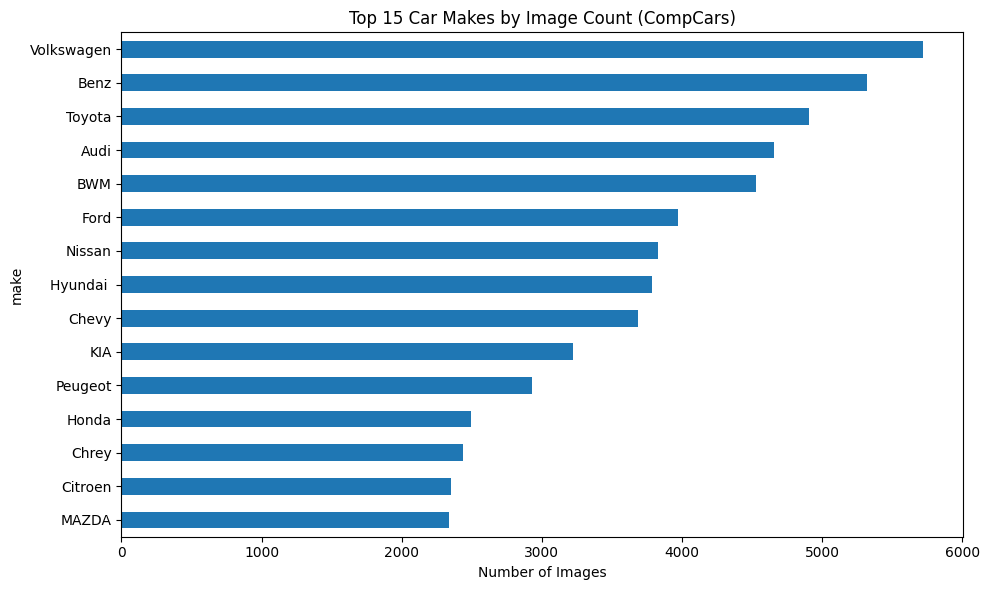

In [32]:
# --- Visual: top 15 makes as a bar chart ---
import matplotlib.pyplot as plt

top_makes = df_final['make'].value_counts().head(15)
plt.figure(figsize=(10, 6))
top_makes.plot(kind='barh')
plt.xlabel('Number of Images')
plt.title('Top 15 Car Makes by Image Count (CompCars)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

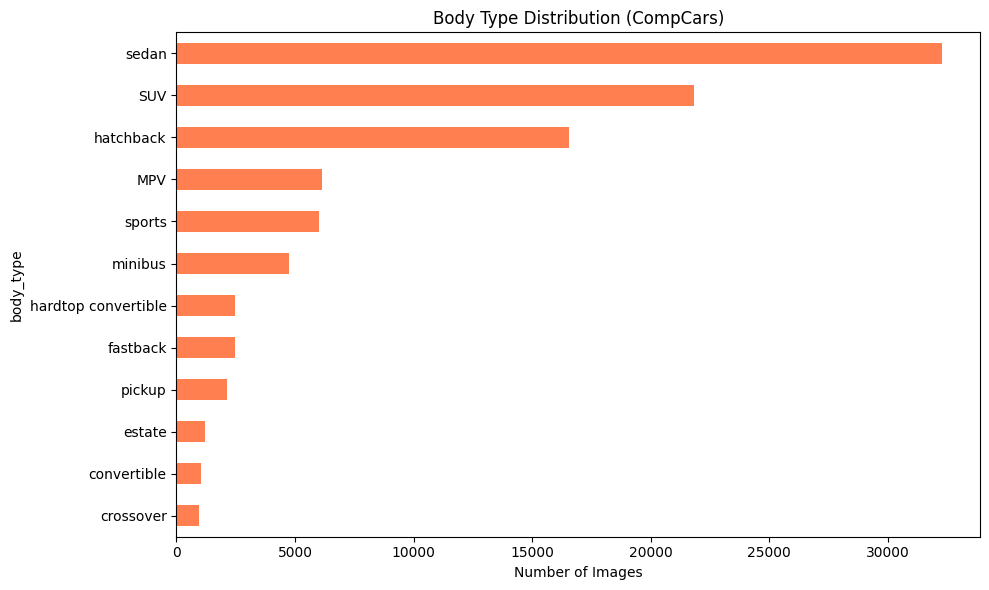

In [33]:
# --- Body type distribution (a chart this time) ---
plt.figure(figsize=(10, 6))
df_final['body_type'].value_counts().plot(kind='barh', color='coral')
plt.xlabel('Number of Images')
plt.title('Body Type Distribution (CompCars)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [34]:
print(f"Duplicate file_paths: {df_final['file_path'].duplicated().sum()}")

Duplicate file_paths: 0


In [35]:
import hashlib
from tqdm import tqdm

def get_image_hash(filepath):
    try:
        with open(filepath, 'rb') as f:
            return hashlib.md5(f.read()).hexdigest()
    except Exception:
        return None


tqdm.pandas(desc='Hashing images')
df_final['image_hash'] = df_final['file_path'].progress_apply(get_image_hash)

duplicate_hashes = df_final['image_hash'].duplicated().sum()
print(f"Duplicate images found (by content): {duplicate_hashes}")

# See which ones, if any
if duplicate_hashes > 0:
    dupes = df_final[df_final.duplicated('image_hash', keep=False)].sort_values('image_hash')
    print(dupes[['file_path', 'make', 'model_name', 'body_type', 'image_hash']].head(20))

Hashing images: 100%|██████████| 136726/136726 [02:51<00:00, 798.31it/s]


Duplicate images found (by content): 52
                                                file_path              make  \
11937   /content/compcars_local/image/77/131/2013/548a...              Benz   
12184   /content/compcars_local/image/77/132/2013/548a...              Benz   
21463   /content/compcars_local/image/41/762/2012/baf8...           Jiulong   
21472   /content/compcars_local/image/41/760/2010/0742...           Jiulong   
12138   /content/compcars_local/image/77/132/2013/4be8...              Benz   
11888   /content/compcars_local/image/77/131/2013/4be8...              Benz   
110476  /content/compcars_local/image/151/421/2010/345...  Changan Business   
110475  /content/compcars_local/image/151/421/2010/ed7...  Changan Business   
11876   /content/compcars_local/image/77/131/2013/fc5c...              Benz   
12128   /content/compcars_local/image/77/132/2013/fc5c...              Benz   
77065   /content/compcars_local/image/111/1708/2008/7e...             Volvo   
76423   /con

In [36]:
# Look at all 52 duplicates to understand the pattern before deciding
dupe_groups = df_final[df_final.duplicated('image_hash', keep=False)].sort_values('image_hash')
print(f"Total duplicate images: {dupe_groups['image_hash'].nunique()} unique images appearing multiple times")
print(f"Total rows involved: {len(dupe_groups)}")

# Check: are labels consistent within each duplicate group, or conflicting?
conflicts = dupe_groups.groupby('image_hash')['model_name'].nunique()
print(f"Duplicate groups with CONFLICTING model labels: {(conflicts > 1).sum()} out of {len(conflicts)}")

Total duplicate images: 52 unique images appearing multiple times
Total rows involved: 104
Duplicate groups with CONFLICTING model labels: 50 out of 52


In [37]:
# Identify image hashes where model_name is ambiguous
conflict_hashes = dupe_groups.groupby('image_hash')['model_name'].nunique()
ambiguous_hashes = conflict_hashes[conflict_hashes > 1].index

# Remove ALL rows tied to ambiguous images (since we can't trust either label)
df_clean = df_final[~df_final['image_hash'].isin(ambiguous_hashes)].copy()

# For the 2 non-conflicting duplicate groups, just keep one copy each
df_clean = df_clean.drop_duplicates(subset='image_hash', keep='first')

print(f"Original: {len(df_final)}")
print(f"After removing ambiguous + deduplicating: {len(df_clean)}")

Original: 136726
After removing ambiguous + deduplicating: 136624


In [38]:
df_clean = df_final.copy()
print(f"Starting: {len(df_clean)}")

# 1. Remove ambiguous duplicates (conflicting labels — can't trust either)
conflict_hashes = dupe_groups.groupby('image_hash')['model_name'].nunique()
ambiguous_hashes = conflict_hashes[conflict_hashes > 1].index
df_clean = df_clean[~df_clean['image_hash'].isin(ambiguous_hashes)]
print(f"After removing ambiguous duplicates: {len(df_clean)}")

# 2. Remove remaining (non-conflicting) duplicates, keep one copy
df_clean = df_clean.drop_duplicates(subset='image_hash', keep='first')
print(f"After deduplicating: {len(df_clean)}")

# 3. Remove rare makes (<100 images) — still a legitimate data-sufficiency filter
make_counts = df_clean['make'].value_counts()
valid_makes = make_counts[make_counts >= 100].index
df_clean = df_clean[df_clean['make'].isin(valid_makes)]
print(f"After removing rare makes: {len(df_clean)}")

# NOTE: body_type is NOT filtered to 6 categories per William's guidance —
# all 12 categories retained, including rows with missing body_type
# (those rows are still valid for make/model tasks, just not body-type training)

print(f"\nFinal dataset: {len(df_clean)} rows")
print(f"Body types retained: {df_clean['body_type'].nunique()} (including NaN for missing)")
print(df_clean['body_type'].value_counts(dropna=False))

Starting: 136726
After removing ambiguous duplicates: 136626
After deduplicating: 136624
After removing rare makes: 135419

Final dataset: 135419 rows
Body types retained: 12 (including NaN for missing)
body_type
NaN                    37901
sedan                  32232
SUV                    21702
hatchback              16534
MPV                     6149
sports                  5987
minibus                 4638
hardtop convertible     2473
fastback                2473
pickup                  2134
estate                  1215
convertible             1047
crossover                934
Name: count, dtype: int64


In [39]:
df_clean.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_modeling_ready.csv', index=False)
print(f"Saved {len(df_clean)} rows to compcars_modeling_ready.csv")

Saved 135419 rows to compcars_modeling_ready.csv


In [40]:
df_clean['file_path'] = df_clean['file_path'].str.replace(
    '/content/compcars_local/',
    '/content/drive/MyDrive/capstone-vehicle-metadata/data/compcars_kaggle/extracted/',
    regex=False
)

df_clean.to_csv('/content/drive/MyDrive/capstone-vehicle-metadata/outputs/compcars_modeling_ready.csv', index=False)
print("Saved with corrected, shareable file paths.")

Saved with corrected, shareable file paths.
